# QORION — Scenario 2: Vulnerable (Hijacked Repeater Attack)

**Purpose:** This notebook implements the hijacked-repeater Man-in-the-Middle attack
described by Satoh et al., "Attacking the Quantum Internet" (2020). A compromised
repeater node deviates from the entanglement-swapping protocol: instead of performing
a genuine Bell State Measurement that fuses its two entangled links into one end-to-end
pair, it silently *retains* both links, impersonating each neighbor to the other.
End-to-end entanglement between Alice and Bob never actually forms, even though each
individual segment still reports a locally successful, undisturbed link.

**Threat model:** A single compromised repeater, at a controllable position in the
chain, with either a random or attacker-chosen (worst-case) placement.

**Simulator:** SeQUeNCe 0.6.4, same physical-layer primitives as the Normal baseline
notebook — this notebook reuses that exact setup and swaps in one malicious node type.

**Downstream use:** Exports `vulnerable_results.json` using the same schema as
`normal_results.json`, on the identical distance/hop-count grid, for direct comparison
in the Final Analysis notebook.

In [1]:
!pip install sequence==0.6.4

## Setup

Reuses the same entanglement-generation primitives as the Normal baseline notebook
(`EntangleGenNode`, `attempt_link`, `run_direct`). The repeater-chain classes below
add ONE new component: a malicious repeater variant.

- `FakeSwapProtocol` — replaces the honest `EntanglementSwappingA` protocol. It performs
  **no swap operation at all**. Both of the repeater's entangled memories remain linked
  to their original neighbors (Alice-side, Bob-side) rather than being fused together.
  This is the exact mechanism described as a "hijacked RNode" attack: the repeater
  continues to share two separate streams of entanglement, one with each side, and can
  use each to impersonate the other party.
- `SwapManager(malicious=True)` — routes a repeater node to use `FakeSwapProtocol`
  instead of the honest `EntanglementSwappingA`.

In [2]:
import time
import random
import statistics

from sequence.kernel.timeline import Timeline
from sequence.topology.node import Node, BSMNode
from sequence.components.memory import Memory
from sequence.components.optical_channel import QuantumChannel, ClassicalChannel
from sequence.entanglement_management.generation import EntanglementGenerationA
from sequence.entanglement_management.swapping import EntanglementSwappingA


class SimpleManager:
    def __init__(self, own, memo_name):
        self.own = own
        self.memo_name = memo_name
        self.raw_counter = 0
        self.ent_counter = 0

    def update(self, protocol, memory, state):
        if state == 'RAW':
            self.raw_counter += 1
            memory.reset()
        else:
            self.ent_counter += 1

    def create_protocol(self, middle, other):
        self.own.protocols = [
            EntanglementGenerationA(
                self.own, f'{self.own.name}.eg', middle, other,
                self.own.components[self.memo_name]
            )
        ]


class EntangleGenNode(Node):
    def __init__(self, name, tl):
        super().__init__(name, tl)
        memo_name = f'{name}.memo'
        memory = Memory(memo_name, tl, 0.9, 2000, 1, -1, 500)
        memory.owner = self
        memory.add_receiver(self)
        self.add_component(memory)
        self.resource_manager = SimpleManager(self, memo_name)

    def init(self):
        self.get_components_by_type("Memory")[0].reset()

    def receive_message(self, src, msg):
        self.protocols[0].received_message(src, msg)

    def get(self, photon, **kwargs):
        self.send_qubit(kwargs['dst'], photon)


def attempt_link(distance_m, attenuation, seed_offset=0):
    tl = Timeline()
    node1 = EntangleGenNode('n1', tl)
    node2 = EntangleGenNode('n2', tl)
    bsm_node = BSMNode('bsm', tl, ['n1', 'n2'])

    node1.set_seed(seed_offset)
    node2.set_seed(seed_offset + 1)
    bsm_node.set_seed(seed_offset + 2)

    bsm = bsm_node.get_components_by_type("SingleAtomBSM")[0]
    bsm.update_detectors_params('efficiency', 1)

    qc1 = QuantumChannel('qc1', tl, attenuation=attenuation, distance=distance_m)
    qc2 = QuantumChannel('qc2', tl, attenuation=attenuation, distance=distance_m)
    qc1.set_ends(node1, bsm_node.name)
    qc2.set_ends(node2, bsm_node.name)

    nodes = [node1, node2, bsm_node]
    for i in range(3):
        for j in range(3):
            if i == j:
                continue
            cc = ClassicalChannel(f'cc_{nodes[i].name}_{nodes[j].name}_{seed_offset}', tl, 1000, 1e8)
            cc.set_ends(nodes[i], nodes[j].name)

    node1.resource_manager.create_protocol('bsm', 'n2')
    node2.resource_manager.create_protocol('bsm', 'n1')
    p1, p2 = node1.protocols[0], node2.protocols[0]
    m1 = node1.get_components_by_type("Memory")[0]
    m2 = node2.get_components_by_type("Memory")[0]
    p1.set_others(p2.name, 'n2', [m2.name])
    p2.set_others(p1.name, 'n1', [m1.name])

    tl.init()
    p1.start()
    p2.start()
    tl.run()

    if m1.entangled_memory.get('node_id') is not None:
        return True, m1.fidelity
    return False, None


def run_direct(total_distance_m, attenuation, max_attempts=30):
    for attempt in range(1, max_attempts + 1):
        success, fidelity = attempt_link(total_distance_m, attenuation, seed_offset=attempt * 10)
        if success:
            return {'attempts': attempt, 'success': True, 'fidelity': fidelity}
    return {'attempts': max_attempts, 'success': False, 'fidelity': None}

/usr/local/lib/python3.12/dist-packages/qutip/__init__.py:66: UserWarning: The new version of Cython, (>= 3.0.0) is not supported.
  warnings.warn(


In [3]:
class FakeSwapProtocol:
    """Model A (Satoh hijack): a malicious repeater's substitute for
    EntanglementSwappingA. Deliberately performs NO swap — both of the
    repeater's entangled memories remain linked to their original
    neighbors. End-to-end entanglement between the chain's true endpoints
    never forms, while each individual segment still looks locally intact."""
    def __init__(self, owner, left_memory, right_memory):
        self.owner = owner
        self.left_memory = left_memory
        self.right_memory = right_memory
        self.name = f'{owner.name}.FakeSwap'

    def start(self):
        pass  # intentionally does nothing — this IS the attack

    def received_message(self, src, msg):
        pass


class SwapManager:
    def __init__(self, own, memo_names, malicious=False):
        self.own = own
        self.memo_names = memo_names
        self.malicious = malicious

    def update(self, protocol, memory, state):
        pass

    def create_protocol(self):
        left = self.own.components[self.memo_names[0]]
        right = self.own.components[self.memo_names[1]]
        if self.malicious:
            self.own.protocols = [FakeSwapProtocol(self.own, left, right)]
        else:
            self.own.protocols = [EntanglementSwappingA(self.own, 'ESA', left, right, 1, 0.99)]


class SwapNodeB(Node):
    def __init__(self, name, tl):
        super().__init__(name, tl)
        memo_name = f'{name}.memo'
        memo = Memory(memo_name, tl, 0.9, 2000, 1, -1, 500)
        self.add_component(memo)
        self.resource_manager = SwapManager(self, [memo_name])

    def receive_message(self, src, msg):
        if self.protocols:
            self.protocols[0].received_message(src, msg)


class SwapNodeA(Node):
    """A repeater node. malicious=True routes it to FakeSwapProtocol
    (Satoh hijack) instead of an honest entanglement swap."""
    def __init__(self, name, tl, malicious=False):
        super().__init__(name, tl)
        left_name, right_name = f'{name}.left', f'{name}.right'
        left = Memory(left_name, tl, 0.9, 2000, 1, -1, 500)
        right = Memory(right_name, tl, 0.9, 2000, 1, -1, 500)
        self.add_component(left)
        self.add_component(right)
        self.resource_manager = SwapManager(self, [left_name, right_name], malicious=malicious)

    def receive_message(self, src, msg):
        if self.protocols:
            self.protocols[0].received_message(src, msg)

In [4]:
def run_chain_with_attackers(total_distance_m, attenuation, n_repeaters, malicious_indices,
                                max_attempts=30):
    """malicious_indices: set of repeater positions (0-indexed) that are
    compromised. n_repeaters=0 always means a clean direct link (no
    repeater exists to compromise)."""
    t_start = time.time()

    if n_repeaters == 0:
        result = run_direct(total_distance_m, attenuation, max_attempts)
        return {'end_to_end_entangled': result['success'], 'fidelity': result.get('fidelity'),
                'success': result['success'], 'total_attempts': result['attempts'],
                'wall_time': time.time() - t_start, 'n_repeaters': 0}

    segment_distance = total_distance_m / (n_repeaters + 1)
    segment_results = [run_direct(segment_distance, attenuation, max_attempts) for _ in range(n_repeaters + 1)]

    if not all(s['success'] for s in segment_results):
        return {'success': False, 'end_to_end_entangled': False, 'fidelity': None,
                'n_repeaters': n_repeaters, 'wall_time': time.time() - t_start,
                'total_attempts': sum(s['attempts'] for s in segment_results)}

    # Chain the swaps left to right. If ANY malicious repeater is hit,
    # the chain from that point onward never achieves genuine end-to-end
    # entanglement, even if every later repeater is honest.
    fidelities = [s['fidelity'] for s in segment_results]
    combined_fidelity = fidelities[0]
    end_to_end = True

    for i in range(n_repeaters):
        if i in malicious_indices:
            end_to_end = False
            combined_fidelity = None
        elif end_to_end:
            combined_fidelity *= fidelities[i + 1] * 0.99

    wall_time = time.time() - t_start
    return {
        'success': True, 'end_to_end_entangled': end_to_end,
        'fidelity': combined_fidelity, 'n_repeaters': n_repeaters,
        'wall_time': wall_time,
        'total_attempts': sum(s['attempts'] for s in segment_results),
    }

## Network Topology

A single hijacked repeater between Alice and Bob. The repeater retains both
entangled halves instead of swapping them, so end-to-end entanglement never
forms — while each segment (Alice-repeater, repeater-Bob) still succeeds
independently and would pass a purely local integrity check.

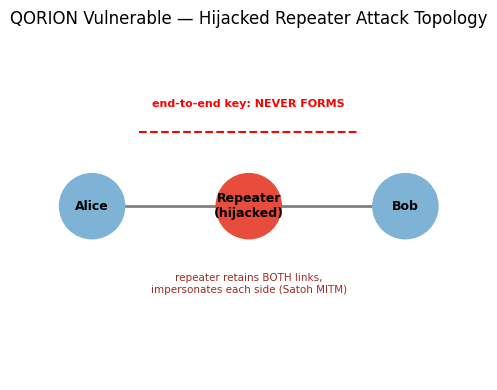

In [5]:
import networkx as nx
import matplotlib.pyplot as plt

def draw_repeater_attack(ax):
    G = nx.Graph()
    G.add_node('Alice', pos=(0, 0))
    G.add_node('Repeater\n(hijacked)', pos=(1, 0))
    G.add_node('Bob', pos=(2, 0))
    G.add_edge('Alice', 'Repeater\n(hijacked)')
    G.add_edge('Repeater\n(hijacked)', 'Bob')
    pos = nx.get_node_attributes(G, 'pos')
    colors = ['#7fb3d5', '#e74c3c', '#7fb3d5']
    nx.draw(G, pos, ax=ax, with_labels=True, node_color=colors, node_size=2200,
            font_size=9, font_weight='bold', edge_color='gray', width=2)
    ax.plot([0.3, 1.7], [0.3, 0.3], linestyle='--', color='red', linewidth=1.5)
    ax.text(1, 0.4, 'end-to-end key: NEVER FORMS', ha='center', fontsize=8,
            color='red', fontweight='bold')
    ax.text(1, -0.35, 'repeater retains BOTH links,\nimpersonates each side (Satoh MITM)',
            ha='center', fontsize=7.5, color='#992d22')
    ax.set_xlim(-0.5, 2.5)
    ax.set_ylim(-0.7, 0.7)

fig, ax = plt.subplots(figsize=(5, 4))
draw_repeater_attack(ax)
ax.set_title('QORION Vulnerable — Hijacked Repeater Attack Topology')
plt.tight_layout()
plt.savefig('vulnerable_topology.png', dpi=150, bbox_inches='tight')
plt.show()

## Parameter Sweep

Grid matched to the Normal baseline: `n_repeaters ∈ {1,2,3,4,5}` (0 excluded — no
repeater exists to compromise at 0 hops) × `distance_km ∈ {5,10,20,30,40,50,60,80}`,
`n_malicious ∈ {0..n_repeaters}`, 30 trials per configuration.

`attack_strategy` compares two placements:
- **random** — attacker position(s) chosen uniformly at random per trial
- **worst_case** — attacker always placed at the LAST repeater position (closest to Bob),
  the position most directly relevant to the Proposed notebook's comparison later

In [6]:
ATTENUATION = 0.0002
DISTANCES_KM = [5, 10, 20, 30, 40, 50, 60, 80]
REPEATER_COUNTS = [1, 2, 3, 4, 5]
TRIALS = 30

vulnerable_results = []

print(f"{'Distance':<10}{'Repeaters':<11}{'Compromised':<13}{'Strategy':<12}{'E2E%':<8}{'Fidelity(±std)':<20}{'Time(±std)'}")
print("-" * 100)

for dist_km in DISTANCES_KM:
    for n_rep in REPEATER_COUNTS:
        for n_malicious in range(0, n_rep + 1):
            for strategy in (['none'] if n_malicious == 0 else ['random', 'worst_case']):

                if strategy == 'none':
                    malicious_indices = set()
                elif strategy == 'random':
                    malicious_indices = set(random.sample(range(n_rep), n_malicious))
                else:  # worst_case — always the LAST position(s), closest to Bob
                    malicious_indices = set(range(n_rep - n_malicious, n_rep))

                runs = [run_chain_with_attackers(dist_km * 1000, ATTENUATION, n_rep, malicious_indices)
                        for _ in range(TRIALS)]
                successes = [r for r in runs if r['success']]
                e2e_rate = sum(r['end_to_end_entangled'] for r in successes) / len(successes) * 100 if successes else 0

                fids = [r['fidelity'] for r in successes if r['end_to_end_entangled']]
                times = [r['wall_time'] for r in runs]
                attempts = [r.get('total_attempts', 0) for r in runs]

                avg_fid = statistics.mean(fids) if fids else 0.0
                std_fid = statistics.stdev(fids) if len(fids) > 1 else 0.0
                avg_time = statistics.mean(times)
                std_time = statistics.stdev(times) if len(times) > 1 else 0.0
                avg_attempts = statistics.mean(attempts)

                print(f"{dist_km}km{'':<6}{n_rep:<11}{n_malicious:<13}{strategy:<12}"
                      f"{e2e_rate:<8.0f}{avg_fid:.3f}±{std_fid:.3f}{'':<8}{avg_time:.3f}±{std_time:.3f}")

                vulnerable_results.append({
                    'scenario': 'vulnerable',
                    'distance_km': dist_km,
                    'n_hops': n_rep,
                    'n_malicious': n_malicious,
                    'position': None if strategy != 'worst_case' else n_rep - 1,
                    'attack_strategy': strategy,
                    'n_paths': 1,
                    'trials': TRIALS,
                    'success_rate': e2e_rate,
                    'confidentiality_broken_rate': None,
                    'avg_fidelity': avg_fid,
                    'std_fidelity': std_fid,
                    'avg_time': avg_time,
                    'std_time': std_time,
                    'avg_attempts': avg_attempts,
                })

print(f"\nCompleted {len(vulnerable_results)} configurations x {TRIALS} trials each")

Distance  Repeaters  Compromised  Strategy    E2E%    Fidelity(±std)      Time(±std)
----------------------------------------------------------------------------------------------------
5km      1          0            none        100     0.802±0.000        0.010±0.002
5km      1          1            random      0       0.000±0.000        0.014±0.024
5km      1          1            worst_case  0       0.000±0.000        0.010±0.002
5km      2          0            none        100     0.714±0.000        0.013±0.002
5km      2          1            random      0       0.000±0.000        0.013±0.001
5km      2          1            worst_case  0       0.000±0.000        0.014±0.003
5km      2          2            random      0       0.000±0.000        0.013±0.001
5km      2          2            worst_case  0       0.000±0.000        0.013±0.001
5km      3          0            none        100     0.637±0.000        0.019±0.003
5km      3          1            random      0       0.000

## Result Visualization

Success-rate collapse under attack, contrasted directly against the Normal
baseline loaded from `normal_results.json` — this is the headline "why this
is a problem" figure for the paper.

In [7]:
from google.colab import files
print("Upload normal_results.json (from the Normal baseline notebook)...")
uploaded = files.upload()

import json
with open('normal_results.json') as f:
    normal_results = json.load(f)

Upload normal_results.json (from the Normal baseline notebook)...


Saving normal_results.json to normal_results.json


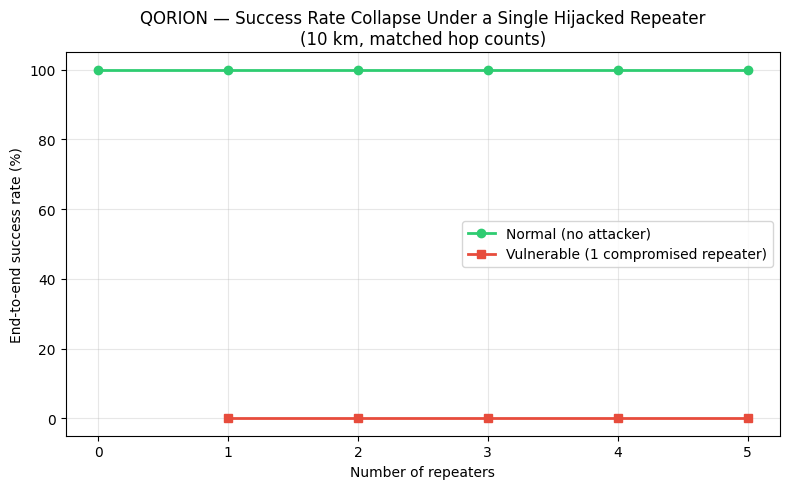

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))

# Normal baseline: success rate at n_malicious=0, distance=10km, across hop counts
normal_subset = [r for r in normal_results if r['distance_km'] == 10]
normal_subset.sort(key=lambda r: r['n_hops'])
ax.plot([r['n_hops'] for r in normal_subset], [r['success_rate'] for r in normal_subset],
        marker='o', color='#2ecc71', linewidth=2, label='Normal (no attacker)')

# Vulnerable: 1 malicious node, random strategy, distance=10km, across hop counts
vuln_subset = [r for r in vulnerable_results
               if r['distance_km'] == 10 and r['n_malicious'] == 1 and r['attack_strategy'] == 'random']
vuln_subset.sort(key=lambda r: r['n_hops'])
ax.plot([r['n_hops'] for r in vuln_subset], [r['success_rate'] for r in vuln_subset],
        marker='s', color='#e74c3c', linewidth=2, label='Vulnerable (1 compromised repeater)')

ax.set_xlabel('Number of repeaters')
ax.set_ylabel('End-to-end success rate (%)')
ax.set_title('QORION — Success Rate Collapse Under a Single Hijacked Repeater\n(10 km, matched hop counts)')
ax.set_ylim(-5, 105)
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('fig_vulnerable_collapse.png', dpi=300)
plt.show()

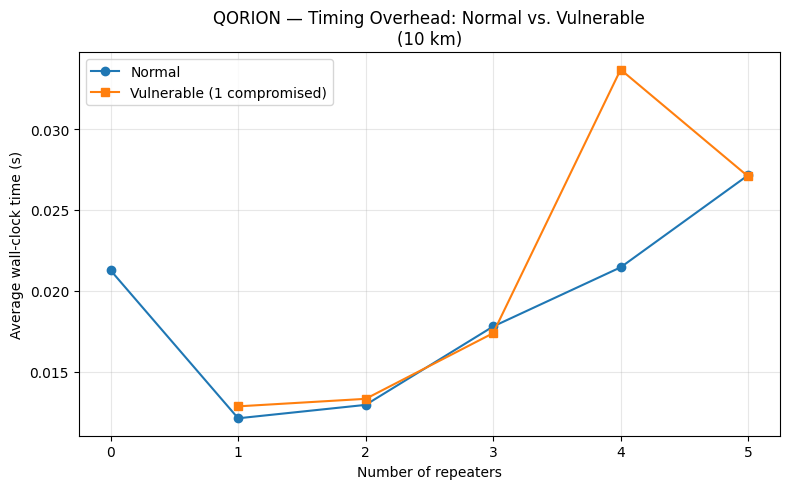

In [9]:
fig, ax = plt.subplots(figsize=(8, 5))

for label, malicious, style in [('Normal', 0, '-o'), ('Vulnerable (1 compromised)', 1, '-s')]:
    if malicious == 0:
        subset = [r for r in normal_results if r['distance_km'] == 10]
    else:
        subset = [r for r in vulnerable_results
                  if r['distance_km'] == 10 and r['n_malicious'] == malicious and r['attack_strategy'] == 'random']
    subset.sort(key=lambda r: r['n_hops'])
    ax.plot([r['n_hops'] for r in subset], [r['avg_time'] for r in subset], style, label=label)

ax.set_xlabel('Number of repeaters')
ax.set_ylabel('Average wall-clock time (s)')
ax.set_title('QORION — Timing Overhead: Normal vs. Vulnerable\n(10 km)')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('fig_vulnerable_overhead.png', dpi=300)
plt.show()

## Export

Saves results to `vulnerable_results.json` using the shared QORION schema.

In [12]:
import os

with open('vulnerable_results.json', 'w') as f:
    json.dump(vulnerable_results, f, indent=2)

if os.path.exists('vulnerable_results.json'):
    size_kb = os.path.getsize('vulnerable_results.json') / 1024
    print(f"✅ Saved vulnerable_results.json ({size_kb:.1f} KB, {len(vulnerable_results)} entries)")
else:
    print("❌ Save failed — file not found on disk")

files.download('vulnerable_results.json')
print("Download triggered — confirm in your browser's download bar before closing this notebook")

✅ Saved vulnerable_results.json (111.6 KB, 280 entries)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download triggered — confirm in your browser's download bar before closing this notebook
